# Unsupervised NILM: Disaggregating Household Smart-Meter Data

**Non-intrusive load monitoring (NILM) of 200 households, without labels.**
DTU 46765 *Machine Learning for Energy Systems* · Kaggle competition, autumn 2026

A smart meter reports one number per hour. This notebook splits that number into the four things that actually
consumed it: **always-on devices**, **electric heating**, **EV charging** and **other** household activity.
There are **no labels**: no training set says how much of any hour was heating. Everything is inferred from the
structure of the signal, from a simulator calibrated to that structure, and from leaderboard submissions designed
as *measurements* of the hidden truth.

| | |
|---|---|
| **Input** | 200 households × 5,112 hours (1 Jan – 31 Jul 2024) of total kWh, plus outdoor temperature |
| **Output** | 4 components per household-hour (1,022,400 rows × 4) |
| **Metric** | mean squared error against the hidden true components (the leaderboard uses all the test data) |
| **Result** | **0.00194**, a 37 % lower error than the first model (0.00310). **2nd** on the final leaderboard (winner: 0.00189) |

**How to read this notebook.** It follows the order in which things were discovered. Each section ends with the
lesson it taught, and section 13 collects them all.

**Contents**
1. Data and preprocessing
2. Fingerprinting households (clustering)
3. Anatomy of each component
4. Learning from the leaderboard: probing the hidden truth
5. Refining the model: EV session shape, meter noise, partial first hours
6. The missing piece: a calibrated simulator
7. A hidden Markov model for always-on and other
8. Leaderboard stacking
9. A common daily heating factor
10. Every submission is a measurement: the megastack
11. The last day: testing physical hypotheses
12. Results
13. Lessons learned
14. Submission, validation and how to reproduce

In [1]:
import sys, os, pickle
sys.path.insert(0, os.path.abspath('../src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)   # silence font-weight fallback notices

import data, disaggregate as dis, insights, submission, viz, simulate, stack
viz.setup()
FIG = '../figures'
os.makedirs(FIG, exist_ok=True)

res_v1 = dis.run('v1')           # first model (~30 s), used to tell the discovery story
res = dis.run('v2c')             # heating and EV stage of the final model (~40 s)
X, temp, ts = res.X, res.temp, res.ts
hour, weekend, t_daily, hdd = data.calendar(ts, temp)
types = res.household_type

# The HMM stages take ~10 min each, so their outputs are cached by src/run_v3.py and src/make_stack.py
load = lambda name: dict(np.load(f'../data/base_{name}.npz'))
v2c, v4, stack14 = load('v2c'), load('v4'), load('stack14')

def load_sub(name):
    # a scored submission file as {component: array[household, hour]}
    d = pd.read_csv(f'../submissions/{name}.csv')
    return {c: d[f'{c}_kWh'].values.reshape(X.shape[0], -1) for c in viz.STACK}

final = load_sub('31_final_megastack_30_files_evhours')
print(f'{X.shape[0]} households x {X.shape[1]} hours; final model = submission 31 (leaderboard 0.00194)')

200 households x 5112 hours; final model = submission 31 (leaderboard 0.00194)


### One meter, four hidden sources

One week of a household that owns both an EV and electric heating. The black line is all the meter sees; the
coloured layers are the final model's estimate of each source.

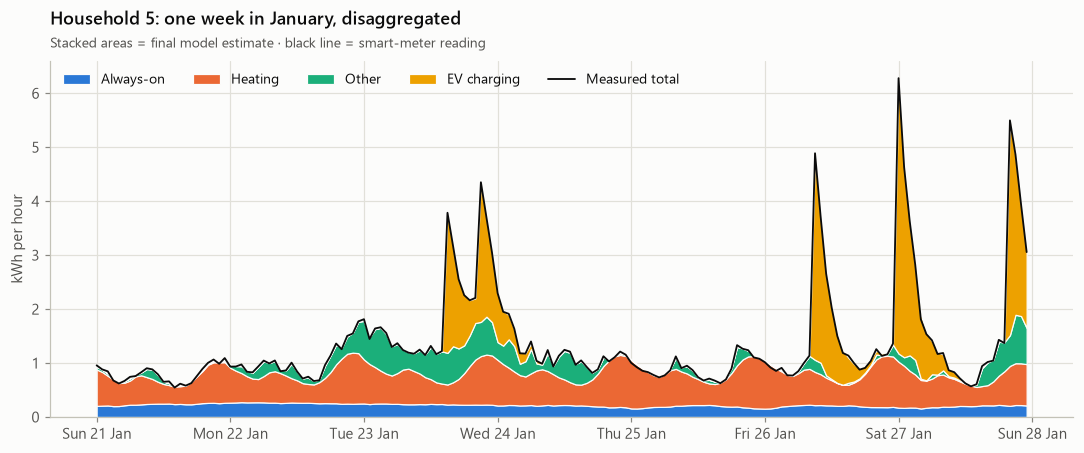

In [2]:
i = 5                                            # an EV + heating household
s = slice(24 * 20, 24 * 27)
fig, ax = plt.subplots(figsize=(12, 4.2))
viz.stacked(ax, ts[s], {c: final[c][i, s] for c in viz.STACK}, total=X[i, s])
viz.style_dates(ax)
viz.title(ax, f'Household {i}: one week in January, disaggregated',
          'Stacked areas = final model estimate · black line = smart-meter reading')
fig.savefig(f'{FIG}/hero.png'); plt.show()

## 1 · Data and preprocessing

The raw file is in long format: one row per *(household, hour)*, with `consumption_kWh` and `temperature_C`.

In [3]:
raw = data.read_raw()
display(raw.head(3))
data.quality_report(raw)

,kaggle_id,household_id,timestamp,consumption_kWh,temperature_C
0,0_2024-01-01 00,0,2024-01-01 00:00:00,0.4597,-1.91
1,0_2024-01-01 01,0,2024-01-01 01:00:00,0.6231,-4.20
2,0_2024-01-01 02,0,2024-01-01 02:00:00,0.8293,-2.44


,value
rows,1022400
households,200
hours per household,5112–5112
period,2024-01-01 → 2024-07-31 23:00
complete hourly grid (no gaps / DST jumps),True
missing values,0
"duplicate (household, timestamp)",0
"kaggle_id == ""<household>_<YYYY-MM-DD HH>""",True
temperature identical across households,True
negative readings,0


**Preprocessing was minimal, and that was deliberate.**

* **Reshape.** The long table becomes a dense matrix `X[household, hour]` (200 × 5,112). Every later step is a
  time-series operation on one household's row, so this keeps the code simple and fast.
* **Calendar features.** Hour of day, a weekend flag and the **daily mean temperature** (section 3.2 shows why).
* **No cleaning needed.** No missing values, no duplicates, no DST gaps, identical temperature for every household.
* **No outlier removal.** Readings of 20+ kWh are EV charging sessions, exactly what we need to recover.
* **No smoothing of the raw data.** It would blur the sharp EV onsets. Noise is removed *inside* the model instead.

> **Lesson 1.** In a reverse-engineering problem, "outliers" and "noise" are often the signal. Look before you clean.

## 2 · Fingerprinting households

The competition hint: first work out *who owns what*. Two scalar fingerprints separate the households.

* **EV.** A charging session draws 2–26 kWh in an hour; households without an EV never exceed ~2 kWh.
* **Heating.** Each household is regressed on a heating signal `max(0, 20.5 − T_daily)`; heating households have a
  slope *t*-statistic far above 5, the rest sit around 0.

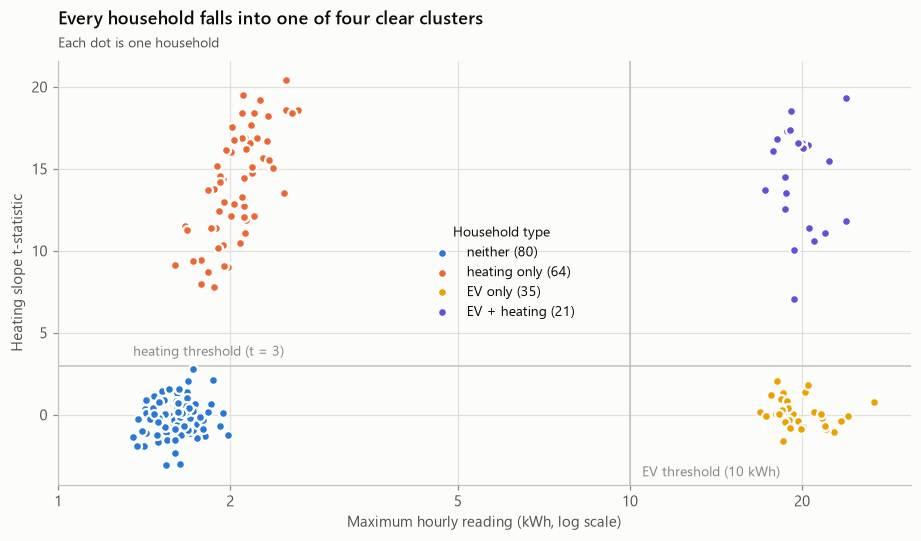

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for name, col in viz.TYPE_COLORS.items():
    m = types == name
    ax.scatter(X.max(1)[m], res.k_t[m], s=34, color=col, edgecolor=viz.SURFACE, linewidth=1.5,
               label=f'{name} ({m.sum()})', zorder=3)
ax.set_xscale('log'); ax.set_xticks([1, 2, 5, 10, 20]); ax.set_xticklabels(['1', '2', '5', '10', '20'])
ax.minorticks_off()
ax.axvline(dis.EV_MAX_THR, color=viz.AXIS, lw=1); ax.axhline(dis.HEAT_T_THR, color=viz.AXIS, lw=1)
ax.text(dis.EV_MAX_THR * 1.05, ax.get_ylim()[0] + 0.5, 'EV threshold (10 kWh)', color=viz.MUTED, fontsize=9)
ax.text(X.max(1).min(), dis.HEAT_T_THR + 0.6, 'heating threshold (t = 3)', color=viz.MUTED, fontsize=9)
ax.set_xlabel('Maximum hourly reading (kWh, log scale)'); ax.set_ylabel('Heating slope t-statistic')
viz.title(ax, 'Every household falls into one of four clear clusters', 'Each dot is one household')
ax.legend(loc='center', bbox_to_anchor=(0.52, 0.5), title='Household type', title_fontsize=9)
fig.savefig(f'{FIG}/fingerprints.png'); plt.show()

**Does a proper clustering algorithm agree?** The data file is literally called `kaggle_clustering`, so here is
the check: K-means and a Gaussian mixture on the same two standardised fingerprints.

In [5]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

F = StandardScaler().fit_transform(np.c_[np.log(X.max(1)), res.k_t])
pd.DataFrame({'adjusted Rand index vs rule-based groups': [
    adjusted_rand_score(types, KMeans(4, n_init=20, random_state=0).fit_predict(F)),
    adjusted_rand_score(types, GaussianMixture(4, n_init=10, random_state=0).fit_predict(F))]},
    index=['K-means (k = 4)', 'Gaussian mixture (4 components)']).round(3)

,adjusted Rand index vs rule-based groups
K-means (k = 4),0.993
Gaussian mixture (4 components),1.000


The Gaussian mixture matches exactly; K-means misplaces one household (it prefers round clusters of similar size).

> **Lesson 2.** The "obvious" step (classification) was solved in a day. The score is decided by the *magnitudes*,
> and that is where all the remaining work went.

## 3 · Anatomy of each component

The data is synthetic, so each component follows a simple rule. Pinning these rules down is what turns an
unsupervised problem into a tractable estimation problem.

### 3.1 EV charging: a sharp start followed by decay

Aligned at their start and divided by their peak, isolated charging sessions collapse onto one curve, roughly
`A · r^k` with r ≈ 0.69 per hour. (Section 5 refines this shape.)

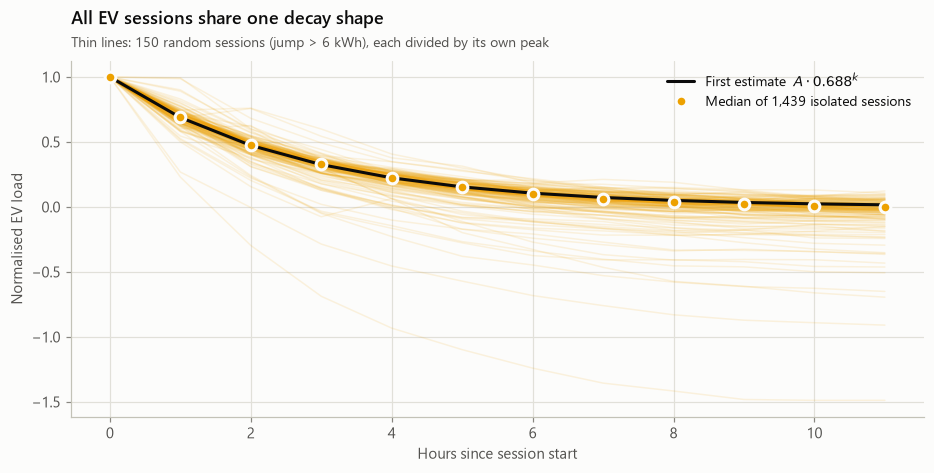

In [6]:
shapes, amps, starts = insights.ev_event_shapes(X, res.has_ev, jump=6)
k = np.arange(shapes.shape[1])
fig, ax = plt.subplots(figsize=(10, 4.2))
rng = np.random.default_rng(0)
for sh in shapes[rng.choice(len(shapes), 150, replace=False)]:
    ax.plot(k, sh, color=viz.COLORS['ev'], alpha=0.12, lw=1)
ax.plot(k, dis.R_EV ** k, color=viz.INK, lw=2, label=f'First estimate  $A\\cdot{dis.R_EV}^k$')
ax.plot(k, np.median(shapes, 0), 'o', color=viz.COLORS['ev'], ms=7, mec=viz.SURFACE, mew=2,
        label=f'Median of {len(shapes):,} isolated sessions')
ax.set_xlabel('Hours since session start'); ax.set_ylabel('Normalised EV load')
viz.title(ax, 'All EV sessions share one decay shape', 'Thin lines: 150 random sessions (jump > 6 kWh), each divided by its own peak')
ax.legend(); fig.savefig(f'{FIG}/ev_kernel.png'); plt.show()

**The deconvolution trick.** If every session is `A · r^k`, then `u_t = x_t − r · x_{t−1}` cancels the tail and leaves
**a single spike of height A at the session start**. Detecting sessions reduces to thresholding `u`.

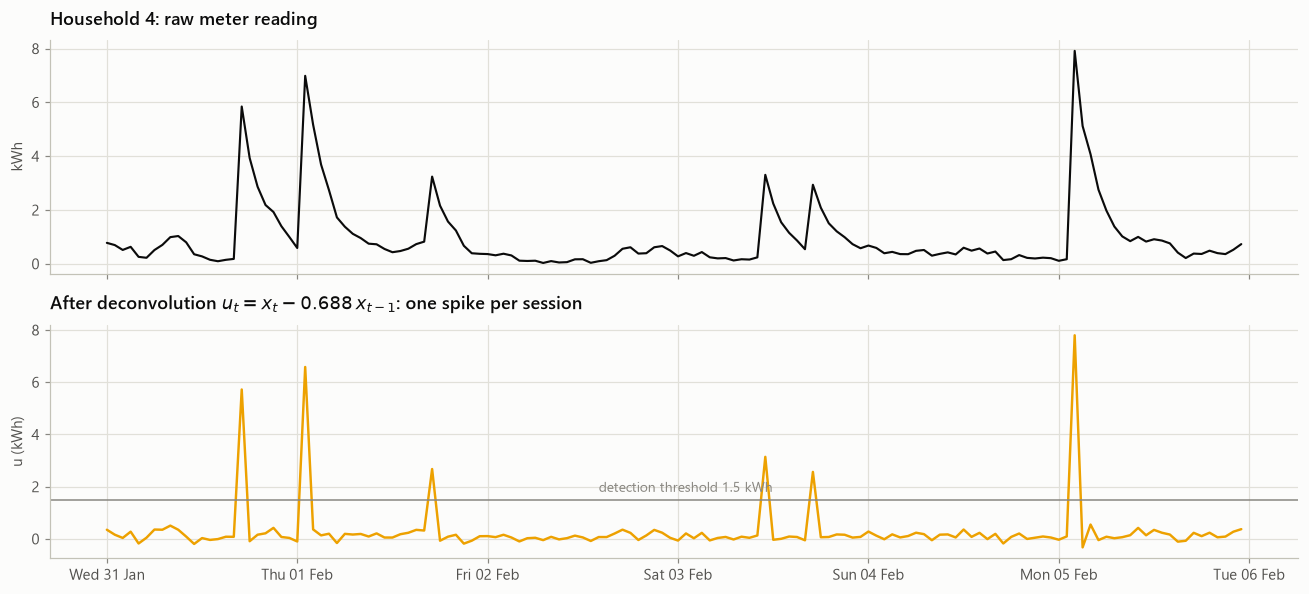

In [7]:
i, s = 4, slice(24 * 30, 24 * 36)
u = dis.deconvolve(X[i])
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(ts[s], X[i, s], color=viz.INK, lw=1.4)
axes[0].set_ylabel('kWh'); viz.title(axes[0], f'Household {i}: raw meter reading')
axes[1].plot(ts[s], u[s], color=viz.COLORS['ev'], lw=1.6)
axes[1].axhline(dis.EV_START_THR, color=viz.MUTED, lw=1)
axes[1].text(ts[s][62], dis.EV_START_THR + 0.3, f'detection threshold {dis.EV_START_THR} kWh', color=viz.MUTED, fontsize=9)
axes[1].set_ylabel('u (kWh)'); viz.title(axes[1], r'After deconvolution $u_t = x_t - 0.688\,x_{t-1}$: one spike per session')
viz.style_dates(axes[1]); fig.tight_layout(); fig.savefig(f'{FIG}/ev_deconvolution.png'); plt.show()

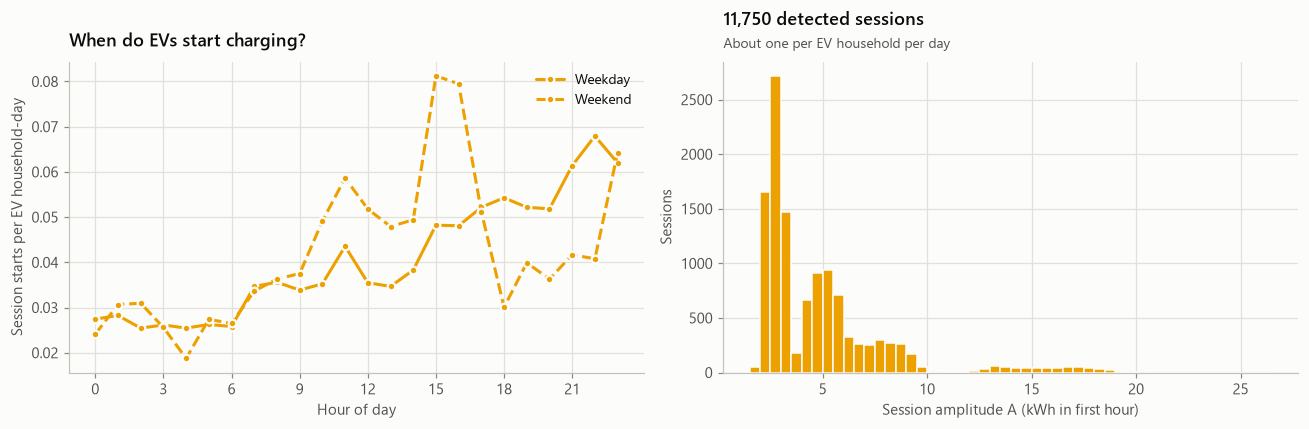

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
all_starts = np.concatenate(starts)
wk = weekend[all_starts].astype(bool)
for lab, m, ls in [('Weekday', ~wk, '-'), ('Weekend', wk, '--')]:
    n_days = (weekend[::24] == (lab == 'Weekend')).sum()
    axes[0].plot(range(24), np.bincount(hour[all_starts][m], minlength=24) / n_days / res.has_ev.sum(),
                 marker='o', ls=ls, color=viz.COLORS['ev'], ms=5, mec=viz.SURFACE, mew=1.5, label=lab)
axes[0].set_xlabel('Hour of day'); axes[0].set_ylabel('Session starts per EV household-day')
viz.title(axes[0], 'When do EVs start charging?'); axes[0].legend(); axes[0].set_xticks(range(0, 24, 3))
axes[1].hist(amps, bins=np.arange(1.5, 27, 0.5), color=viz.COLORS['ev'], edgecolor=viz.SURFACE)
axes[1].set_xlabel('Session amplitude A (kWh in first hour)'); axes[1].set_ylabel('Sessions')
viz.title(axes[1], f'{len(amps):,} detected sessions', 'About one per EV household per day')
fig.tight_layout(); plt.show()

### 3.2 Heating: linear in how cold the *day* is

Average heating household minus average non-heating household = mean heating load. Against **daily mean**
temperature it is a hinge: ~0 above 20.5 °C and linear below. Hourly temperature, 6–48 h rolling means and
exponential smoothing all fit worse.

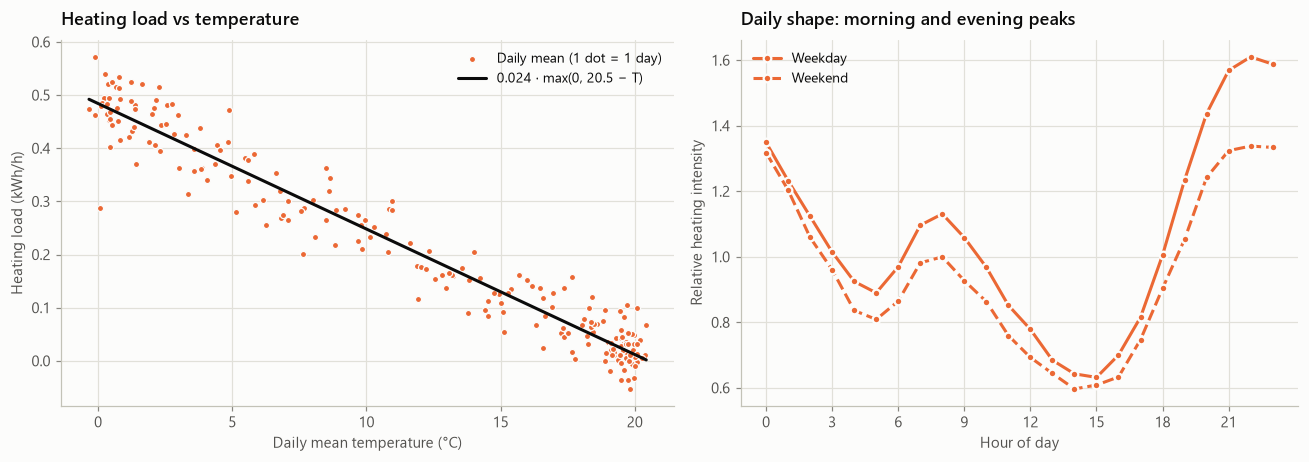

In [9]:
heat_rows = np.where(types == 'heating only')[0]; pure_rows = np.where(types == 'neither')[0]
exc = insights.heating_excess_daily(X, heat_rows, pure_rows)
td = t_daily[::24]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
ax.scatter(td, exc, s=16, color=viz.COLORS['heating'], edgecolor=viz.SURFACE, linewidth=0.8, label='Daily mean (1 dot = 1 day)')
grid = np.linspace(td.min(), td.max(), 200); hd = np.maximum(0, 20.5 - grid)
slope = np.dot(np.maximum(0, 20.5 - td), exc) / np.dot(np.maximum(0, 20.5 - td), np.maximum(0, 20.5 - td))
ax.plot(grid, slope * hd, color=viz.INK, lw=2, label=f'{slope:.3f} · max(0, 20.5 − T)')
ax.set_xlabel('Daily mean temperature (°C)'); ax.set_ylabel('Heating load (kWh/h)')
viz.title(ax, 'Heating load vs temperature'); ax.legend()
ax = axes[1]
for w, lab, ls in [(0, 'Weekday', '-'), (1, 'Weekend', '--')]:
    ax.plot(range(24), res.hp[w], marker='o', ls=ls, color=viz.COLORS['heating'], ms=5, mec=viz.SURFACE, mew=1.5, label=lab)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel('Hour of day'); ax.set_ylabel('Relative heating intensity')
viz.title(ax, 'Daily shape: morning and evening peaks'); ax.legend()
fig.tight_layout(); fig.savefig(f'{FIG}/heating.png'); plt.show()

**Is the heating model's structure right?** Three likelihood tests on every heating household came back
negative: a household-specific hourly profile, a household-specific threshold temperature and a curved
(quadratic) temperature response all improve the fit by exactly what chance alone would give. Heating is one
number per household (its scale `k_h`) times a shared shape.

### 3.3 Other: bursts with memory

After removing each household's average daily profile, the "other" load behaves like an **AR(1) process with
φ ≈ 0.89** per hour: a burst of activity typically lasts several hours.

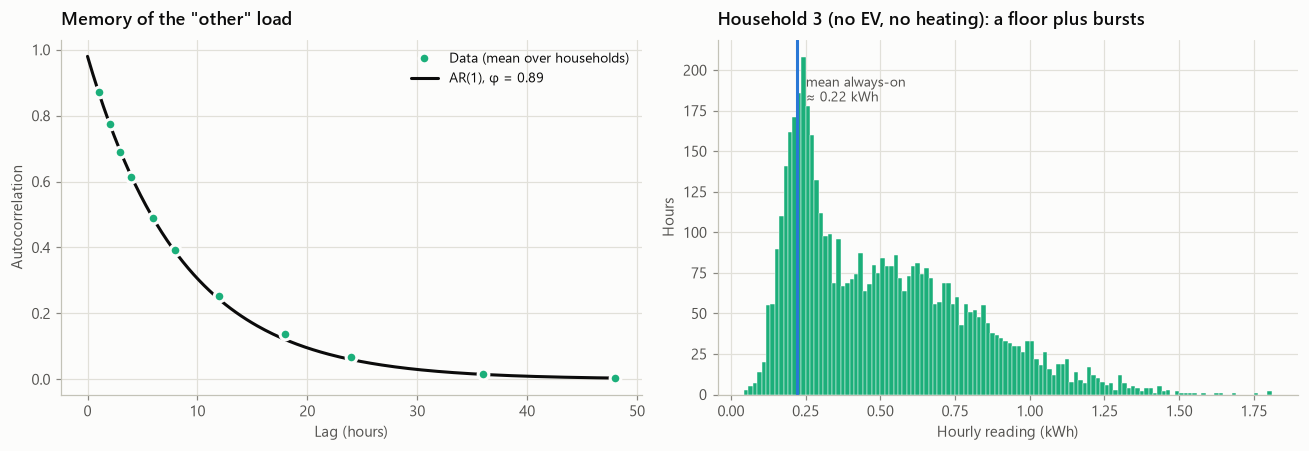

In [10]:
lags = np.array([1, 2, 3, 4, 6, 8, 12, 18, 24, 36, 48])
A = insights.residual_acf(X, pure_rows, hour, weekend, lags)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(lags, A.mean(0), 'o', color=viz.COLORS['other'], ms=7, mec=viz.SURFACE, mew=2, label='Data (mean over households)', zorder=3)
ll = np.linspace(0, 48, 200); ax.plot(ll, 0.98 * dis.PHI ** ll, color=viz.INK, lw=2, label=f'AR(1), φ = {dis.PHI}')
ax.set_xlabel('Lag (hours)'); ax.set_ylabel('Autocorrelation'); viz.title(ax, 'Memory of the "other" load'); ax.legend()
ax = axes[1]; i = 3
ax.hist(X[i], bins=120, color=viz.COLORS['other'], edgecolor=viz.SURFACE, linewidth=0.3)
lvl = final['always_on'][i].mean()
ax.axvline(lvl, color=viz.COLORS['always_on'], lw=2)
ax.text(lvl + 0.03, ax.get_ylim()[1] * 0.9, f'mean always-on\n≈ {lvl:.2f} kWh', color=viz.INK_2, fontsize=9, va='top')
ax.set_xlabel('Hourly reading (kWh)'); ax.set_ylabel('Hours')
viz.title(ax, f'Household {i} (no EV, no heating): a floor plus bursts')
fig.tight_layout(); fig.savefig(f'{FIG}/other.png'); plt.show()

### 3.4 Always-on: a floor that is not flat

The histogram is **bimodal**: a sharp peak near the household's floor (hours when "other" is idle) and a broad
tail of activity. The first model took always-on as a constant, the mode of the lower peak. That turned out to
be the single biggest mistake of the project. Section 6 shows how a simulator revealed that the floor **drifts**
by about ±0.05 kWh over hours to days.

> **Lesson 3.** Synthetic data is generated by simple rules. Each rule you pin down exactly (a decay ratio, a
> threshold temperature, an AR coefficient) removes a whole class of errors at once.

## 4 · Learning from the leaderboard: probing the hidden truth

Without labels, nothing on our side can measure the error. The leaderboard can, and the algebra of MSE turns each
submission into a **measurement**. If a prediction $p$ is changed to $p'$, the score changes by

$$
4N\,(S' - S) \;=\; \sum (p'^2 - p^2) \;-\; 2\sum (p' - p)\,y .
$$

Everything except $\sum (p' - p)\,y$ is known, so the score difference reveals the inner product between a
perturbation **we choose** and the **hidden truth** $y$. Before each probe we computed the score it would get if the
base model were exact; the gap between that and the observed score is the measurement.

Because this leaderboard is computed on **all** the test data, these measurements are exact (up to the
5-decimal rounding) and there is no public/private split to overfit.

,base_score,expected,public_score,finding
file,,,,
02_probe_always_on_shift,0.003100,0.00355,0.00396,always-on overestimated by 0.0137 kWh/h on ave...
03_probe_meter_noise,0.003006,0.00301,0.00300,white noise sigma~0.037 belongs to no componen...
04_probe_ev_scale,0.003006,0.00680,0.00528,EV underestimated ~2%: true session kernel dec...
05_probe_heating_scale,0.003006,0.00319,0.00312,heating scale ~1.02: level essentially right
07_probe_always_on_spread,0.002580,0.00303,0.00279,per-household always-on levels mostly right: o...
08_probe_always_on_follows_quiet,0.002580,0.00270,0.00251,ALWAYS-ON FLUCTUATES: following quiet readings...
15_probe_ev_scale_on_14,0.002110,0.00309,0.00290,EV still underestimated after the HMM: optimal...


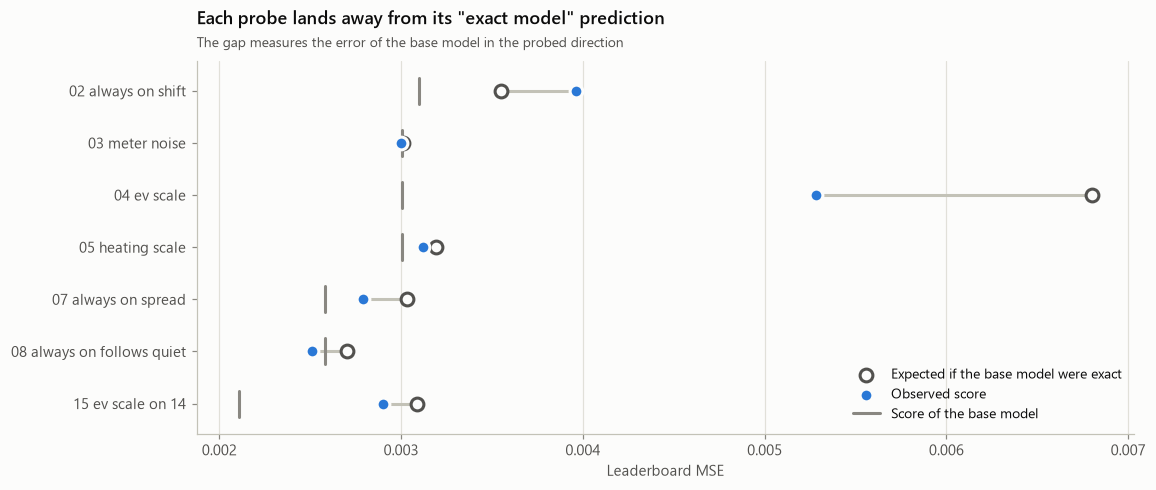

In [11]:
log = insights.leaderboard()
def base_score(b):
    import re
    m = re.search(r'\(([\d.]+)\)', str(b))
    return float(m.group(1)) if m else float(log.set_index('n').loc[int(str(b)[:2]), 'public_score'])
probes = log[(log.kind == 'probe') & log.public_score.notna() & (log.n <= 15)].copy()    # later probes: sections 10-11
probes['base_score'] = probes.base.map(base_score)
probes['expected'] = pd.to_numeric(probes.expected_if_base_exact, errors='coerce')
display(probes[['file', 'base_score', 'expected', 'public_score', 'finding']].set_index('file'))

fig, ax = plt.subplots(figsize=(11, 4.4))
names = probes.file.str.replace(r'^(\d+)_probe_', r'\1 ', regex=True).str.replace('_', ' ')
y = np.arange(len(probes))[::-1]
for yy, b, e, o in zip(y, probes.base_score, probes.expected, probes.public_score):
    ax.plot([e, o], [yy, yy], color=viz.AXIS, lw=2, zorder=1)
    ax.plot([b, b], [yy - 0.25, yy + 0.25], color=viz.MUTED, lw=2)
ax.scatter(probes.expected, y, s=70, facecolor=viz.SURFACE, edgecolor=viz.INK_2, linewidth=2, label='Expected if the base model were exact', zorder=2)
ax.scatter(probes.public_score, y, s=70, color=viz.COLORS['always_on'], edgecolor=viz.SURFACE, linewidth=2, label='Observed score', zorder=3)
ax.plot([], [], color=viz.MUTED, lw=2, label='Score of the base model')
ax.set_yticks(y); ax.set_yticklabels(names); ax.grid(axis='y', visible=False)
ax.set_xlabel('Leaderboard MSE')
viz.title(ax, 'Each probe lands away from its "exact model" prediction', 'The gap measures the error of the base model in the probed direction')
ax.legend(loc='lower right'); fig.savefig(f'{FIG}/probes.png'); plt.show()

What the probes revealed, in order:

| Probe | Question | Answer |
|---|---|---|
| **02** always-on shift | Is the always-on level biased? | 0.0137 kWh/h too high on average |
| **03** meter noise | Where does the small white noise (σ ≈ 0.037) belong? | **To no component**: it is meter noise |
| **04** EV scale | Is EV biased? | ~2 % too low → re-estimate the session shape |
| **05** heating scale | Is heating biased? | Scale ≈ 1.02: essentially right |
| **07** always-on spread | Are per-household always-on levels right? | Mostly (optimal shrink 13 %) |
| **08** quiet-hour follow | Is always-on really flat? | **No, it fluctuates**: led to sections 6–7 |
| **15** EV scale (final) | Is EV still biased after everything? | Only +0.5 %: well calibrated |

The probes of the last two days (21–29) asked finer questions; they are in sections 10 and 11.

> **Lesson 4.** A metric you cannot compute locally can still be *queried*. Design each submission to answer one
> question, and compute the "null" score before submitting so the result is interpretable.

## 5 · Refining the model: EV session shape, meter noise, partial first hours

**v2a.** Instead of assuming a geometric decay, a free kernel κ₀…κ₃₅ shared by all ~11,700 sessions is estimated
by alternating least squares (amplitudes given the kernel, then the kernel given the amplitudes). It decays
~0.70/h, not 0.688, and **ends after ~16 h**, when the battery is full. Meter noise is removed from "other" with
a Kalman smoother, and a feasibility projection keeps every component non-negative.

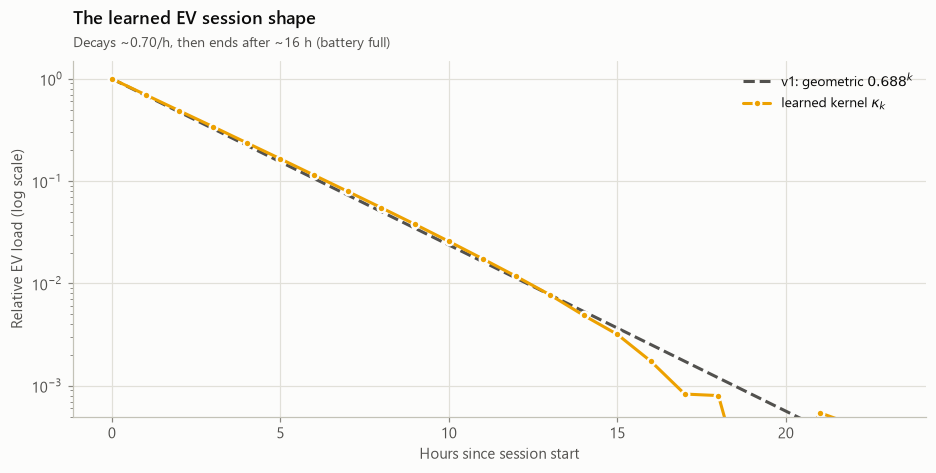

In [12]:
kk = np.arange(24)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(kk, dis.R_EV ** kk, color=viz.INK_2, lw=2, ls='--', label='v1: geometric $0.688^k$')
ax.plot(kk, res.kernel[:24], 'o-', color=viz.COLORS['ev'], ms=5, mec=viz.SURFACE, mew=1.5, label='learned kernel $\\kappa_k$')
ax.set_yscale('log'); ax.set_ylim(5e-4, 1.5)
ax.set_xlabel('Hours since session start'); ax.set_ylabel('Relative EV load (log scale)')
viz.title(ax, 'The learned EV session shape', 'Decays ~0.70/h, then ends after ~16 h (battery full)'); ax.legend()
fig.savefig(f'{FIG}/ev_learned_kernel.png'); plt.show()

**v2c: the first hour is often partial.** After big sessions, the leftover error is not at the start hour but in
hours 1–3. That is the signature of a session that begins at a random minute: the first hour is partial, and a
single amplitude fitted mostly on it gets the whole tail wrong. Giving every session a second, **ridge-shrunk tail
amplitude** (prior sd 3 % of A, so small sessions stay put) removes much of it. The hours used to check this
(2–3) barely inform the tail amplitude, so the improvement there is genuine.

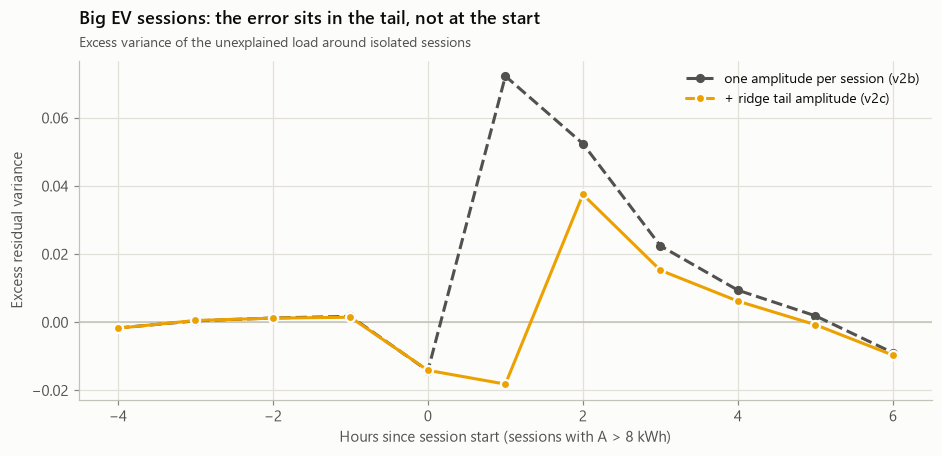

In [13]:
v2b = load('v2b')
def excess_by_lag(P):
    r = X - P['always_on'] - P['heating'] - P['ev']
    dev = np.zeros_like(r)
    for w in (0, 1):
        for h in range(24):
            m = (hour == h) & (weekend == w); dev[:, m] = r[:, m] - r[:, m].mean(1, keepdims=True)
    acc = []
    for i in np.where(res.has_ev)[0]:
        uu = dis.deconvolve(X[i]); st = np.where(uu > 1.5)[0]
        for j, t in enumerate(st):
            if t < 6 or t + 12 >= X.shape[1] or uu[t] < 8: continue
            if (j > 0 and t - st[j - 1] < 16) or (j + 1 < len(st) and st[j + 1] - t < 12): continue
            acc.append(dev[i, t - 4:t + 7])
    v = np.array(acc).var(0); return v - v[:3].mean()
lag = np.arange(-4, 7)
fig, ax = plt.subplots(figsize=(10, 4))
ax.axhline(0, color=viz.AXIS, lw=1)
ax.plot(lag, excess_by_lag(v2b), marker='o', color=viz.INK_2, ls='--', ms=5, label='one amplitude per session (v2b)')
ax.plot(lag, excess_by_lag(v2c), marker='o', color=viz.COLORS['ev'], ms=6, mec=viz.SURFACE, mew=1.5, label='+ ridge tail amplitude (v2c)')
ax.set_xlabel('Hours since session start (sessions with A > 8 kWh)'); ax.set_ylabel('Excess residual variance')
viz.title(ax, 'Big EV sessions: the error sits in the tail, not at the start', 'Excess variance of the unexplained load around isolated sessions')
ax.legend(); fig.savefig(f'{FIG}/ev_tail.png'); plt.show()

> **Lesson 5.** Look at *where* the residual error sits (which hour, which component size). Its pattern names the
> cause. Then validate any fix on data the fix did not use (here: hours 2–3, and a held-out cross-validation).

## 6 · The missing piece: a calibrated simulator

At 0.00239, adding up every error source we knew about explained only about half of the score. To find the rest,
I built a **simulator** (`src/simulate.py`): it regenerates the 200 households with each household's real type and
fitted parameters, but with *known* ground truth. Running our own model on it gives a score we can compute.

In [14]:
sim1 = pickle.load(open('../data/sim1.pkl', 'rb'))      # simulator as first built: flat always-on (+ fast jitter)
sim2 = pickle.load(open('../data/sim2.pkl', 'rb'))      # + slow always-on drift
rows = {}
for name, sim in [('simulator, flat always-on', sim1), ('simulator + slow drift', sim2)]:
    r_sim = dis.run('v2c', data=(sim['Xs'], temp, ts), kernel=sim['kernel'])
    rows[name] = simulate.score(r_sim.pred, sim['truth'])[0]
rows['real data (leaderboard)'] = 0.00239
pd.Series(rows, name='score of model v2c').to_frame().round(5)

,score of model v2c
"simulator, flat always-on",0.00096
simulator + slow drift,0.00218
real data (leaderboard),0.00239


On the first simulator our model scored **0.00096**, less than half its real score. So the real generator contained
something the simulator (and therefore the model) did not. Comparing statistics of real and simulated data, the
glaring difference was **long dips below the always-on level**:

In [15]:
lvl = sim1['a']
r_real = X - v2c['heating'] - v2c['ev']
r_s1 = sim1['Xs'] - sim1['truth']['heating'] - sim1['truth']['ev']
r_s2 = sim2['Xs'] - sim2['truth']['heating'] - sim2['truth']['ev']
tab = pd.DataFrame({f'reading > {d} below level for ≥ {L} h': [len(insights.dip_runs(r, lvl, d, L)) for r in (r_real, r_s1, r_s2)]
                    for d, L in [(0.05, 4), (0.05, 8), (0.05, 12), (0.08, 8)]},
                   index=['real data', 'simulator, flat always-on', 'simulator + slow drift (φ 0.96, σ 0.05)'])
tab

,reading > 0.05 below level for ≥ 4 h,reading > 0.05 below level for ≥ 8 h,reading > 0.05 below level for ≥ 12 h,reading > 0.08 below level for ≥ 8 h
real data,3701,659,160,168
"simulator, flat always-on",424,10,0,0
"simulator + slow drift (φ 0.96, σ 0.05)",3620,628,130,159


The real data has **hundreds of multi-hour stretches** where the reading sits well below the household's
always-on level, in households of every level. "Other" can never be negative, so in those hours the always-on
load itself must have dropped. Adding a **slow AR(1) drift** to always-on (memory of about a day, sd ≈ 0.05 kWh)
reproduces these counts, and the simulated score of the old model jumps to ≈ the real one. **That was the missing
half of the error**: the model kept always-on flat while the truth drifted, pushing the difference (with the
opposite sign) into "other".

> **Lesson 6.** When your error budget does not add up, build a simulator from everything you believe, score your
> model on it, and compare real vs simulated statistics. The statistic that disagrees points at the missing rule.

## 7 · A hidden Markov model for always-on and other

The drift is invisible while "other" is active, and visible only when "other" is idle, which is exactly the setting
for a **hidden Markov model**. Per household and hour, two hidden AR(1) chains on a grid:

$$
\underbrace{w_t}_{\text{always-on drift}},\quad \text{always-on}_t = \max(0, a_h + g(w_t)),
\qquad
\underbrace{z_t}_{\text{latent activity}},\quad \text{other}_t = \max\big(0,\ m_{h}(\text{hour}, \text{weekend}) + s_h z_t\big)
$$

and the observation $x_t - \text{heating}_t - \text{EV}_t = \text{always-on}_t + \text{other}_t + \varepsilon_t$ with meter
noise $\varepsilon_t$ (readings of exactly 0 are treated as censored). The forward–backward algorithm on a
31 × 40 grid gives the exact posterior mean of always-on and other, which **removes the meter noise and tracks the
drift at the same time**. Household parameters ($a_h$, $m_h$, $s_h$) are re-estimated by the method of moments in a
few EM-style passes; households run in parallel (`src/run_v3.py`, ~10 min).

**Choosing the settings without spending submissions.** The forward pass also returns the **log-likelihood** of the
real readings, so every setting can be compared on the real data directly (`src/tune_hmm.py`):

In [16]:
tune = pd.read_csv('../results/hmm_tuning.csv')
best = tune.sort_values('delta_loglik_vs_stage_best', ascending=False).groupby('stage', sort=False).head(3)
best.rename(columns={'delta_loglik_vs_stage_best': 'Δ log-lik vs best in stage'})

,stage,drift_sd,drift_phi,drift_up,sigma_e,other_phi,other_tails,other_scale,Δ log-lik vs best in stage
0,1 drift memory/size/symmetry,0.050,0.93,1.00,0.046,0.90,gaussian,1.0,0.0
51,2 noise and other memory,0.055,0.93,0.75,0.038,0.90,gaussian,1.0,0.0
27,1b shorter memory,0.055,0.93,0.75,0.046,0.90,gaussian,1.0,0.0
60,3 joint noise and drift,0.055,0.91,0.75,0.036,0.90,gaussian,1.0,0.0
78,4 heavy tails / other scale,0.055,0.91,0.75,0.036,0.90,gaussian,1.0,0.0
28,1b shorter memory,0.050,0.93,0.75,0.046,0.90,gaussian,1.0,-11.8
29,1b shorter memory,0.050,0.93,1.00,0.046,0.90,gaussian,1.0,-16.5
61,3 joint noise and drift,0.055,0.93,0.75,0.036,0.90,gaussian,1.0,-19.3
62,3 joint noise and drift,0.060,0.93,0.75,0.036,0.90,gaussian,1.0,-27.9
1,1 drift memory/size/symmetry,0.050,0.96,1.00,0.046,0.90,gaussian,1.0,-43.0


The likelihood chose a drift with **shorter memory** (φ = 0.91 instead of the assumed 0.96), **mildly asymmetric**
(upward excursions ~75 % of downward ones; a downward-only drift is strongly rejected), and an observation noise of
**0.036**, essentially the meter noise measured by probe 03 two days earlier. Heavier-tailed "other" jumps and a
rescaled "other" variance were both rejected. With these settings (v4), the leaderboard score dropped from 0.00222
to **0.00213**.

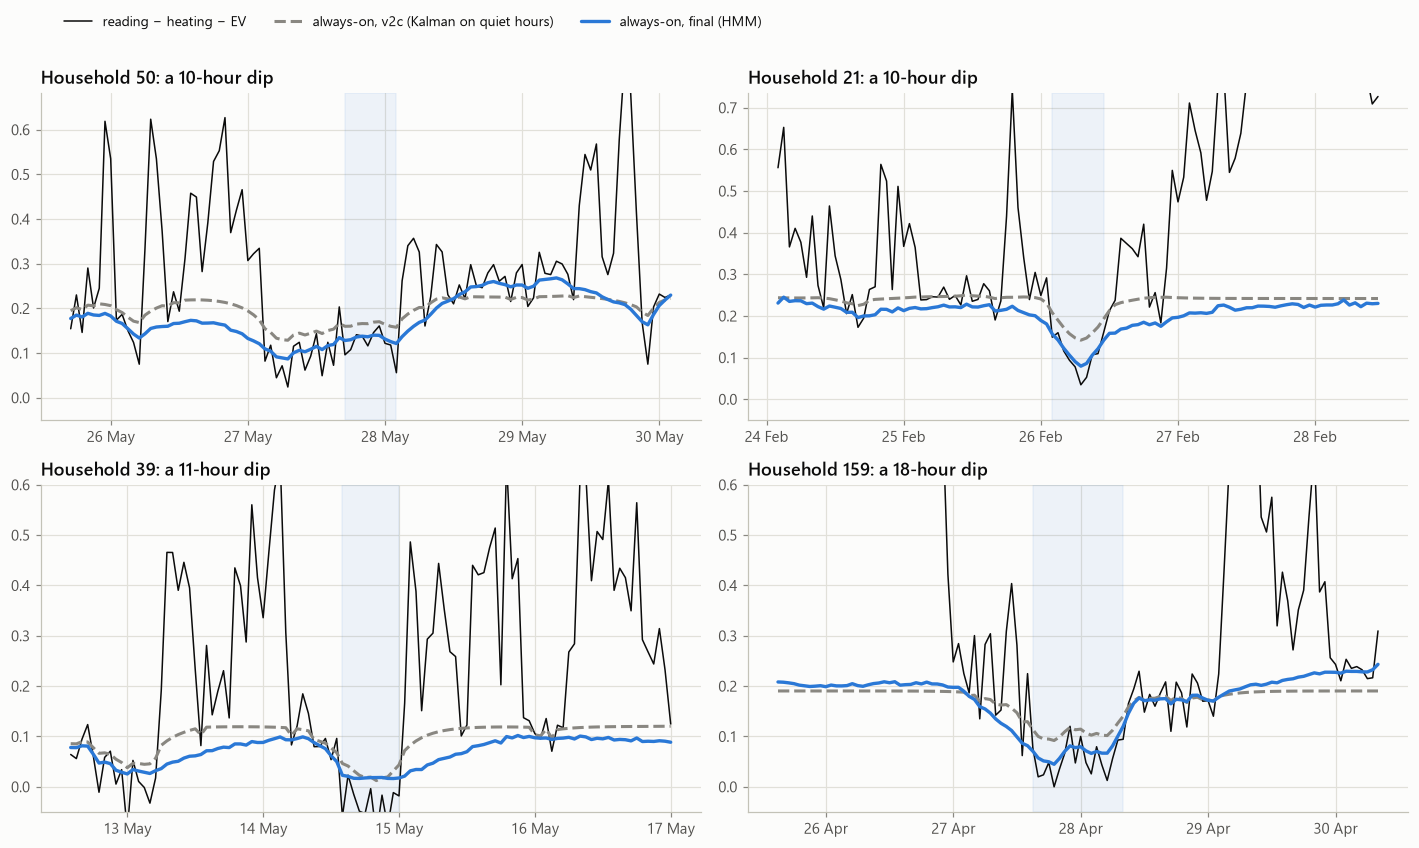

In [17]:
lvl4 = v4['always_on'].mean(1)
runs = insights.dip_runs(X - v2c['heating'] - v2c['ev'], lvl4, 0.05, 10)
pick = [runs[j] for j in np.random.default_rng(3).choice(len(runs), 4, replace=False)]
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, (i, s0, L) in zip(axes.flat, pick):
    w = slice(max(s0 - 48, 0), min(s0 + L + 48, X.shape[1]))
    rr = (X - v2c['heating'] - v2c['ev'])[i, w]
    ax.plot(ts[w], rr, color=viz.INK, lw=1, label='reading − heating − EV')
    ax.plot(ts[w], v2c['always_on'][i, w], color=viz.MUTED, lw=2, ls='--', label='always-on, v2c (Kalman on quiet hours)')
    ax.plot(ts[w], final['always_on'][i, w], color=viz.COLORS['always_on'], lw=2.2, label='always-on, final (HMM)')
    ax.axvspan(ts[s0], ts[s0 + L - 1], color=viz.COLORS['always_on'], alpha=0.07)
    ax.set_ylim(-0.05, max(0.6, lvl4[i] * 3)); viz.style_dates(ax, '%d %b')
    ax.set_title(f'Household {i}: a {L}-hour dip', pad=6)
handles, labels_ = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper left', ncol=3, bbox_to_anchor=(0.04, 1.03))
fig.tight_layout(rect=(0, 0, 1, 0.97)); fig.savefig(f'{FIG}/hmm_drift.png'); plt.show()

In the shaded stretches the reading sinks below the old always-on estimate, which could only follow the quiet hours
weakly. The HMM follows it down, and
during active hours it interpolates the drift from the quiet hours around them.

> **Lesson 7.** Use the likelihood of the *observed* data to choose model settings. It needs no labels and no
> submissions, and it found settings the leaderboard then confirmed.

## 8 · Leaderboard stacking

Since the leaderboard is the final metric and every scored submission is an exact measurement, the scored models
can be **blended optimally**. With a reference $P_0$ (score $s_0$) and others $P_k$ (scores $s_k$), let $D_k = P_k - P_0$.
For a blend $P_0 + \sum_k w_k D_k$ the MSE is exactly

$$
s_0 + \tfrac14\left(w^\top Q\, w + L^\top w\right),\qquad Q_{jk} = \overline{D_j \cdot D_k}\ \text{(known)},\qquad L_k = 4(s_k - s_0) - Q_{kk}\ \text{(from the scores)},
$$

so the best weights are $w = -\tfrac12 Q^{-1} L$ (`src/stack.py`).

In [18]:
checks = pd.DataFrame({
    'blend': ['v2c + 0.70·(v3 − v2c)', 'optimal mix of v2a, v2b, v2c, v3, v4'],
    'predicted before submitting': [0.00218, 0.00212],
    'leaderboard': [0.00218, 0.00211]}).set_index('blend')
checks

,predicted before submitting,leaderboard
blend,,
v2c + 0.70·(v3 − v2c),0.00218,0.00218
"optimal mix of v2a, v2b, v2c, v3, v4",0.00212,0.00211


Both predictions held to the fifth decimal. The gain of the final blend over v4 alone is small (v4 already sits
near the optimum of these directions), but stacking costs nothing and is guaranteed not to be worse.

> **Lesson 8.** When the metric is quadratic, scores are not just rankings. They are linear measurements, and
> several of them can be combined analytically. (Section 10 takes this to its limit.)

## 9 · A common daily heating factor

After the HMM the simulator still scored the model at 0.00135 against 0.00213 on the real data, so something real
was still missing. It turned up when the residuals of the heating households were averaged **across households**
instead of being inspected one at a time.

For every heating household, take what the model leaves unexplained (reading − heating − EV − the household's own
average daily profile) and average it over the 85 heating households, each weighted by its heating scale $k_h$.
Idiosyncratic activity (sd ≈ 0.26 kWh/h per household) averages away; anything **shared** survives. Splitting the
households into two random halves tells the two apart: noise is independent between the halves, a shared signal
is not.

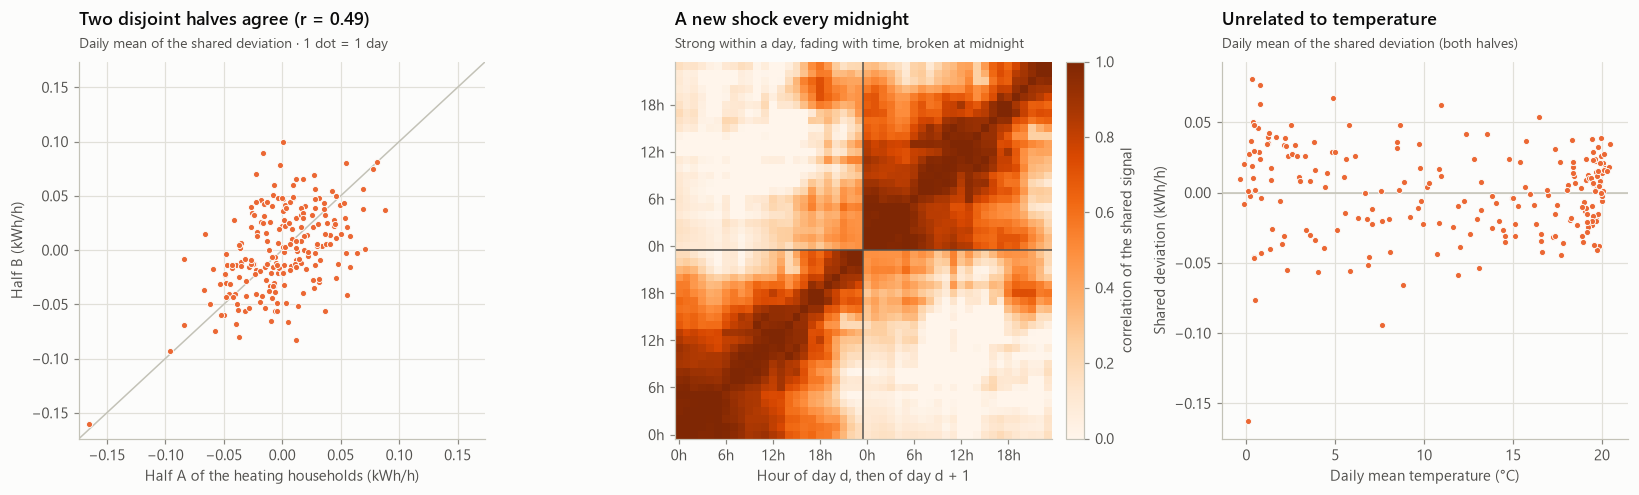

In [19]:
import common_factor as cf
cell = weekend * 24 + hour
H = np.where(v2c['heating'].max(1) > 0)[0]
k = v2c['heating'][H].sum(1) / v2c['heating'][H].sum(1).mean()          # heating scale, mean 1
dev = cf.deviations(X - v2c['heating'] - v2c['ev'], cell, v2c['ev'] < 0.05)[H]
half = np.random.default_rng(0).permutation(len(H)); a, b = half[::2], half[1::2]
GA, GB = cf.weighted_factor(dev[a], k[a]), cf.weighted_factor(dev[b], k[b])
nd = X.shape[1] // 24
daily = lambda g: g.reshape(nd, 24).mean(1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1, 1.15, 1]})
ax = axes[0]
dA, dB = daily(GA), daily(GB)
ax.scatter(dA, dB, s=16, color=viz.COLORS['heating'], edgecolor=viz.SURFACE, linewidth=0.6, zorder=3)
lim = np.abs(np.r_[dA, dB]).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color=viz.AXIS, lw=1); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel('Half A of the heating households (kWh/h)'); ax.set_ylabel('Half B (kWh/h)')
viz.title(ax, f'Two disjoint halves agree (r = {np.corrcoef(dA, dB)[0, 1]:.2f})', 'Daily mean of the shared deviation · 1 dot = 1 day')

ax = axes[1]
blocks = lambda g: np.stack([g[d * 24:(d + 2) * 24] for d in range(nd - 1)])
BA, BB = blocks(GA - GA.mean()), blocks(GB - GB.mean())
C = (BA.T @ BB + BB.T @ BA) / 2 / len(BA)                    # covariance between halves: the noise cancels
corr = C / np.sqrt(np.outer(np.diag(C), np.diag(C)).clip(1e-12))
im = ax.imshow(corr, cmap='Oranges', vmin=0, vmax=1, origin='lower')
ticks = [0, 6, 12, 18, 24, 30, 36, 42]
ax.set_xticks(ticks); ax.set_xticklabels([f'{t % 24}h' for t in ticks]); ax.set_yticks(ticks); ax.set_yticklabels([f'{t % 24}h' for t in ticks])
ax.axhline(23.5, color=viz.INK_2, lw=1); ax.axvline(23.5, color=viz.INK_2, lw=1)
ax.set_xlabel('Hour of day d, then of day d + 1'); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label='correlation of the shared signal')
viz.title(ax, 'A new shock every midnight', 'Strong within a day, fading with time, broken at midnight')

ax = axes[2]
ax.scatter(t_daily[::24], (dA + dB) / 2, s=16, color=viz.COLORS['heating'], edgecolor=viz.SURFACE, linewidth=0.6, zorder=3)
ax.axhline(0, color=viz.AXIS, lw=1)
ax.set_xlabel('Daily mean temperature (°C)'); ax.set_ylabel('Shared deviation (kWh/h)')
viz.title(ax, 'Unrelated to temperature', 'Daily mean of the shared deviation (both halves)')
fig.tight_layout(); fig.savefig(f'{FIG}/heating_factor.png'); plt.show()

**What it is.** A random shock shared by all heating households in proportion to their heating scale. It appears
at midnight, fades over the day (neighbouring hours are almost perfectly correlated, distant ones less so), and the
next midnight brings a new, independent one. It is unrelated to temperature or any calendar feature and worth about
10–18 % of the heating load. In the generator it is presumably a daily random term in heating: weather we are not
shown.

**Estimating it.** In one household it is invisible (≈ 0.03 kWh/h against 0.26 of noise), but the $k$-weighted mean
of 85 households brings the noise down to the size of the signal. A **Wiener filter per day** then shrinks each day by
its signal-to-noise ratio: the signal covariance comes from the cross-covariance of the two halves (the noise
cancels), the noise covariance from their difference, the day's heating level scales the signal, and ±6 h of the
neighbouring days help because the noise does not reset at midnight (`src/common_factor.py`). Split-half
cross-validation says it recovers about 60 % of the factor. Every heating household then gets $k_h \cdot \hat G_t$.

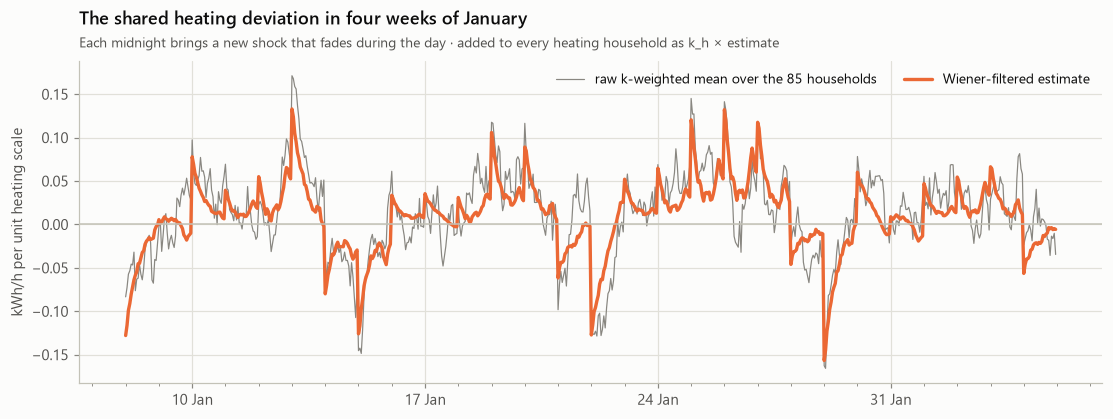

,submission,public_score
n,,
14,stack of v2a–v4 (section 8),0.00211
16,"14 + factor, taken from always-on and other",0.00204
17,v5: factor added before the HMM,0.00205
18,"factor estimator v2 (±6 h context, rank-3 signal)",0.00203
19,v6: v5 with estimator v2,0.00204
20,stack of all 9 models,0.00202


In [20]:
G_hat, _ = cf.estimate(X, v2c['heating'], v2c['ev'], cell)
G_raw = cf.weighted_factor(dev, k)
s = slice(24 * 7, 24 * 35)                                       # four weeks of January
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(ts[s], G_raw[s], color=viz.MUTED, lw=0.8, label='raw k-weighted mean over the 85 households')
ax.plot(ts[s], G_hat[s], color=viz.COLORS['heating'], lw=2.2, label='Wiener-filtered estimate')
ax.axhline(0, color=viz.AXIS, lw=1)
ax.set_ylabel('kWh/h per unit heating scale'); viz.style_dates(ax, '%d %b')
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator(interval=7)); ax.xaxis.set_minor_locator(mdates.DayLocator())
viz.title(ax, 'The shared heating deviation in four weeks of January', 'Each midnight brings a new shock that fades during the day · added to every heating household as k_h × estimate')
ax.legend(loc='upper right', ncol=2); fig.savefig(f'{FIG}/heating_factor_estimate.png'); plt.show()

conf = log.set_index('n').loc[[14, 16, 17, 18, 19, 20], ['public_score']]
conf.insert(0, 'submission', ['stack of v2a–v4 (section 8)', '14 + factor, taken from always-on and other',
                              'v5: factor added before the HMM', 'factor estimator v2 (±6 h context, rank-3 signal)',
                              'v6: v5 with estimator v2', 'stack of all 9 models'])
conf

Moving the factor into heating gained **0.00007 at once** (14 → 16), the largest single step after the HMM. The
probe algebra also decoded the optimal amount: 0.75 of the estimate, so the filter slightly over-trusts its signal;
the stack of all nine models (20, **0.00202**) absorbed that on its own.

> **Lesson 9.** A signal too weak to see in any single unit can be strong across many. Average across units with the
> right loading, and use two disjoint halves to tell a shared signal from noise.

## 10 · Every submission is a measurement: the megastack

Section 8 blended a handful of models. But **every** scored file, probes included, is an exact measurement of one
inner product with the truth, so all of them can enter the blend. Old probes then pay twice: each was built to
measure one bias of an *older* model, and inside the blend it re-measures that bias for the current one.

The catch is **rounding**. Scores are shown with 5 decimals, so every $L_k$ carries noise of known covariance
$\Sigma_L = 16\,\sigma_r^2\,(I + \mathbf{1}\mathbf{1}^\top)$ with $\sigma_r^2 = (10^{-5})^2/12$. With two dozen files many
differences are nearly parallel, $Q$ has tiny eigenvalues, and plain least squares "explains" the rounding with
weights of ±100. The fix (`src/megastack.py`): rotate to the eigenvectors $u$ of $Q$, where each direction is
measured independently with signal $L \cdot u$ and noise $\sqrt{u^\top \Sigma_L u}$; keep only the directions with
$|z| > 3$ and shrink each by $1 - 1/z^2$, which makes its expected gain unbiased.

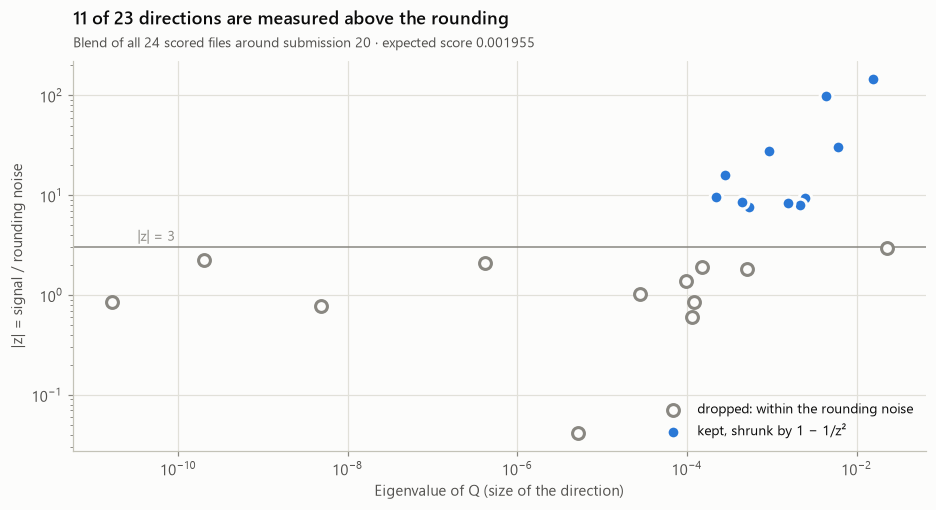

In [21]:
from megastack import load_scored, gram, eigen_select
names_all, scores_all, P_all = load_scored('../results/leaderboard.csv')
use = [j for j, n in enumerate(names_all) if int(n[:2]) <= 24]           # what was known when 25 was built
names24, scores24 = [names_all[j] for j in use], scores_all[use]
P24 = P_all[use]; del P_all
b0 = names24.index('20_stack_all_9_models')
idx, Q = gram(P24, b0); del P24
L = 4 * (scores24[idx] - scores24[b0]) - np.diag(Q)
w, expected, sd, rows = eigen_select(Q, L, scores24[b0])
mu = np.array([r_[0] for r_ in rows]); z = np.abs([r_[1] for r_ in rows]); kept = np.array([r_[2] for r_ in rows])

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.scatter(mu[~kept], z[~kept], s=60, color=viz.SURFACE, edgecolor=viz.MUTED, linewidth=2, label='dropped: within the rounding noise', zorder=3)
ax.scatter(mu[kept], z[kept], s=70, color=viz.COLORS['always_on'], edgecolor=viz.SURFACE, linewidth=2, label='kept, shrunk by 1 − 1/z²', zorder=4)
ax.axhline(3, color=viz.MUTED, lw=1); ax.text(mu.min() * 2, 3.5, '|z| = 3', color=viz.MUTED, fontsize=9)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Eigenvalue of Q (size of the direction)'); ax.set_ylabel('|z| = signal / rounding noise')
viz.title(ax, f'{kept.sum()} of {len(kept)} directions are measured above the rounding',
          f'Blend of all {len(names24)} scored files around submission 20 · expected score {expected:.6f}')
ax.legend(loc='lower right'); fig.savefig(f'{FIG}/megastack.png'); plt.show()

The directions that matter are the large ones; the many tiny ones (bottom left) are differences between nearly
identical files, where any "signal" is rounding. Four new probes, all built on submission 20 with
`src/make_probe.py`, fed the blend:

| Probe | Question | Answer |
|---|---|---|
| **21** always-on drift × 0.5 | Does the HMM drift too much? | No: its scale is right |
| **22** EV hours below 1 kWh × 0.5 | Are the small tail hours of EV sessions real? | Yes, and ~3 % larger |
| **23** heating of EV households × 1.3 | Is heating right where it mixes with EV? | Yes (optimum ≈ 0.99) |
| **24** always-on of EV households + 0.03 | Is their always-on level biased? | **0.014 kWh/h too high** (worth 0.000026) |

| Blend | Predicted before submitting | Leaderboard |
|---|---|---|
| 20 · stack of 9 models | 0.00202 | 0.00202 |
| **25 · megastack of 24 files** | **0.001955** | **0.00195** (1st place on 1 November) |
| 31 · megastack of 30 files + final correction | 0.001948 | 0.00194 |

> **Lesson 10.** Every scored file is an exact measurement, including the "failed" ones, so combine them all. But treat
> the 5-decimal rounding as measurement noise and keep only the directions measured well above it.

## 11 · The last day: testing physical hypotheses

On the last day the leader jumped to **0.00189**. With five submissions left, every idea was first tested offline
(physics, likelihood of the real readings, cross-validation), and only the most promising reached the leaderboard:

| Submission | Idea | Leaderboard | Verdict |
|---|---|---|---|
| **27** | A weakly measured direction of the blend (z = −2.5), re-measured with a 30× larger step | 0.00205 | Rounding noise |
| **28** | Day-to-day part of the always-on drift × 0.5 | 0.00199 | Scale 0.99 ± 0.06: right |
| **29** | Within-day part of the always-on drift × 0.5 | 0.00198 | Scale 1.02 ± 0.09: right |
| **30** | v7: meter noise that grows with consumption + weekly 'other' profile | 0.00197 | No gain |
| **31** | Megastack of all 30 files + always-on de-biasing in EV charging hours | **0.00194** | **Best score** |

**Physical hypotheses checked offline** (the code for the likelihood tests is in `src/hmm_variants.py`):

| Hypothesis | Physics predicts | The data says |
|---|---|---|
| Daylight (dark at 16 h in January, 22 h in July) | more "other" on winter evenings | no seasonal pattern in households without heating |
| Heat-pump efficiency drops in the cold | heating convex in degree-days | heating error vs temperature within noise |
| Danish public holidays | Sunday-like days | the generator ignores them (figure below) |
| Day of the week | — | **Monday is ~27 % weekend-like**: activity carries over from Sunday |
| Always-on changes in steps (appliances switched on for days) | sticky level with jumps | likelihood rejects it (−92 to −587) |
| Meter accuracy is a percentage of the reading | noise grows with consumption | **likelihood +300** (0.8 σ + 4–7 % of the level), but predictions move only 0.005 kWh |
| EV charger at constant power | flat charging blocks | the generator uses a geometric kernel (×0.70/h); ours matches the data within 0.02 kWh |
| A shared daily factor in households without heating | — | real (sd 0.015 kWh/h) but not estimable day by day (cross-validation negative) |

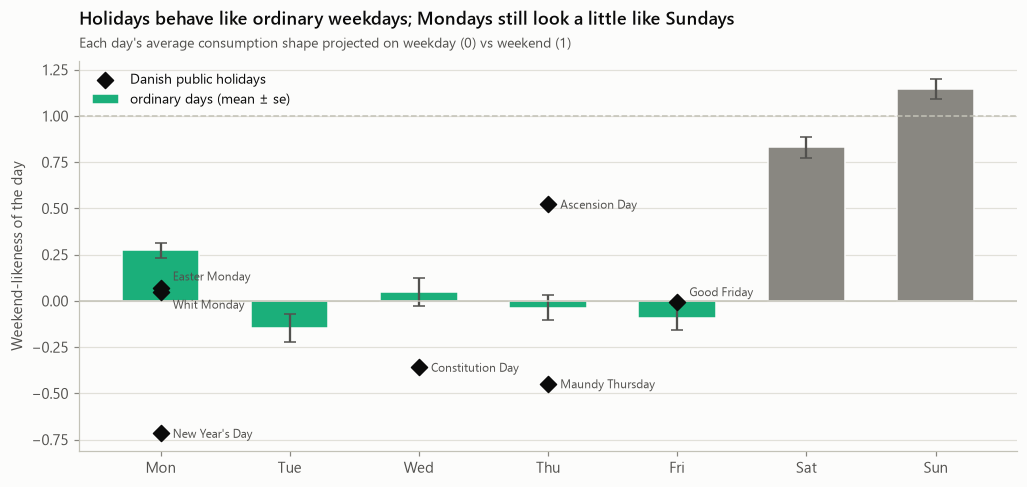

In [22]:
R = X - final['ev'] - final['heating']
Rm = np.where(final['ev'] < 0.05, R, np.nan).reshape(X.shape[0], nd, 24)
days = pd.DatetimeIndex(ts[::24]); dow = days.dayofweek.values; wkd = dow >= 5
pw, pe = np.nanmean(Rm[:, ~wkd], 1), np.nanmean(Rm[:, wkd], 1)          # each household's weekday / weekend profile
shape = (pe - pw).mean(0)                                                # average weekend-minus-weekday shape
beta = np.nanmean(Rm - pw[:, None, :], 0) @ shape / (shape @ shape)      # 0 = weekday-like day, 1 = weekend-like
holidays = {'2024-01-01': "New Year's Day", '2024-03-28': 'Maundy Thursday', '2024-03-29': 'Good Friday',
            '2024-04-01': 'Easter Monday', '2024-05-09': 'Ascension Day', '2024-05-20': 'Whit Monday',
            '2024-06-05': 'Constitution Day'}
hol = np.isin(days, pd.to_datetime(list(holidays)))
wd = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
mean_b = [beta[(dow == d) & ~hol].mean() for d in range(7)]
se_b = [beta[(dow == d) & ~hol].std() / np.sqrt(((dow == d) & ~hol).sum()) for d in range(7)]
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(wd, mean_b, 0.6, yerr=se_b, color=[viz.COLORS['other']] * 5 + [viz.MUTED] * 2, edgecolor=viz.SURFACE,
       error_kw=dict(ecolor=viz.INK_2, lw=1.5, capsize=4), label='ordinary days (mean ± se)')
nudge = {'Easter Monday': (8, 5), 'Whit Monday': (8, -11), 'Good Friday': (8, 4)}
for d_, (dt, name) in zip(np.where(hol)[0], holidays.items()):
    ax.scatter(wd[dow[d_]], beta[d_], marker='D', s=55, color=viz.INK, zorder=4)
    ax.annotate(name, (dow[d_], beta[d_]), textcoords='offset points', xytext=nudge.get(name, (8, -3)), fontsize=8, color=viz.INK_2)
ax.scatter([], [], marker='D', s=55, color=viz.INK, label='Danish public holidays')
ax.axhline(0, color=viz.AXIS, lw=1); ax.axhline(1, color=viz.AXIS, lw=1, ls='--')
ax.set_ylabel('Weekend-likeness of the day'); ax.grid(axis='x', visible=False)
viz.title(ax, 'Holidays behave like ordinary weekdays; Mondays still look a little like Sundays',
          "Each day's average consumption shape projected on weekday (0) vs weekend (1)")
ax.legend(loc='upper left'); fig.savefig(f'{FIG}/weekdays.png'); plt.show()

**The final correction.** Comparing hours of the same (weekend, hour) cell, the always-on of EV households was
**0.0096 kWh/h higher in charging hours** than in hours without charging (standard error 0.0007). The generator's
always-on cannot know whether the car is charging, so this is a model artefact: EV-fit errors that the HMM had
partly absorbed. `src/make_final.py` removes it while keeping each household's always-on mean (already calibrated
by probe 24), splitting the excess of charging hours half to EV and half to other:

In [23]:
from make_final import ev_hours_gap
sub25 = load_sub('25_megastack_24_files')
ev_rows = np.where(final['ev'].max(1) > 2)[0]
pd.DataFrame({'always-on in charging hours minus other hours (kWh/h)': [
    ev_hours_gap(sub25['always_on'], sub25['ev'], cell, ev_rows)[0],
    ev_hours_gap(final['always_on'], final['ev'], cell, ev_rows)[0]]},
    index=['submission 25', 'submission 31 (final)']).round(4)

,always-on in charging hours minus other hours (kWh/h)
submission 25,0.0096
submission 31 (final),0.0000


**What the last day showed.** Every direction the leaderboard can measure says the model is calibrated: the drift at
every time scale (21, 28, 29), the always-on levels by household type (02, 24), the EV and heating scales (04, 05,
15, 23). A model with a clearly better likelihood (v7) moved the predictions by only 0.005 kWh. What is left is
noise-like error in the always-on/other split, hour by hour and household by household, and no probe can remove
that. The winner's 0.00189 shows that about 3 % more was possible, most likely through a better model of exactly
that split.

> **Lesson 11.** Calibrated is not the same as precise. Once every measurable direction says "right", the remaining
> error is noise-like, and only more information (a better model), not more calibration, can reduce it.
>
> **Lesson 12.** A better likelihood is not a better prediction until the posterior moves. Check how much the
> predictions change before spending a submission on a new model.

## 12 · Results

### Score progression

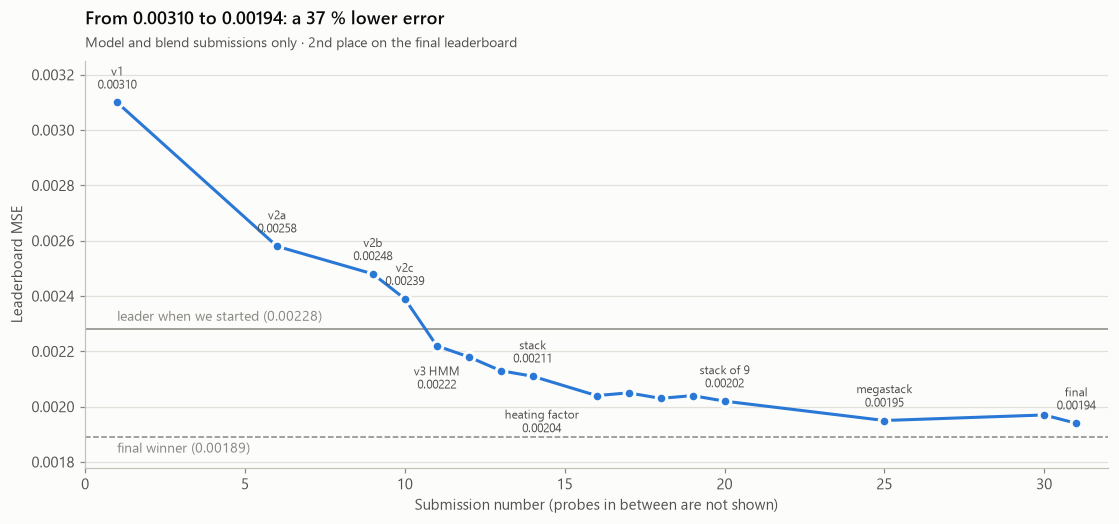

In [24]:
log = insights.leaderboard()
models = log[log.kind == 'model'].dropna(subset=['public_score'])
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(models.n, models.public_score, '-o', color=viz.COLORS['always_on'], ms=7, mec=viz.SURFACE, mew=2, zorder=3)
labels = {1: ('v1', 0, 9), 6: ('v2a', 0, 9), 9: ('v2b', 0, 9), 10: ('v2c', 0, 9), 11: ('v3 HMM', 0, -28),
          14: ('stack', 0, 9), 16: ('heating factor', -36, -24), 20: ('stack of 9', 0, 9), 25: ('megastack', 0, 9),
          31: ('final', 0, 9)}
for n, sc in zip(models.n, models.public_score):
    if n in labels:
        name, dx, dy = labels[n]
        ax.annotate(f'{name}\n{sc:.5f}', (n, sc), textcoords='offset points', xytext=(dx, dy), ha='center', fontsize=8, color=viz.INK_2)
ax.axhline(0.00228, color=viz.MUTED, lw=1)
ax.text(models.n.min(), 0.00228 + 0.00002, 'leader when we started (0.00228)', color=viz.MUTED, fontsize=9, va='bottom')
ax.axhline(0.00189, color=viz.MUTED, lw=1, ls='--')
ax.text(models.n.min(), 0.00189 - 0.00002, 'final winner (0.00189)', color=viz.MUTED, fontsize=9, va='top')
ax.set_xlabel('Submission number (probes in between are not shown)'); ax.set_ylabel('Leaderboard MSE')
ax.set_ylim(0.00178, 0.00325); ax.set_xlim(0, 32); ax.grid(axis='x', visible=False)
viz.title(ax, 'From 0.00310 to 0.00194: a 37 % lower error', 'Model and blend submissions only · 2nd place on the final leaderboard')
fig.savefig(f'{FIG}/score_progress.png'); plt.show()

### One week for each household type (final model)

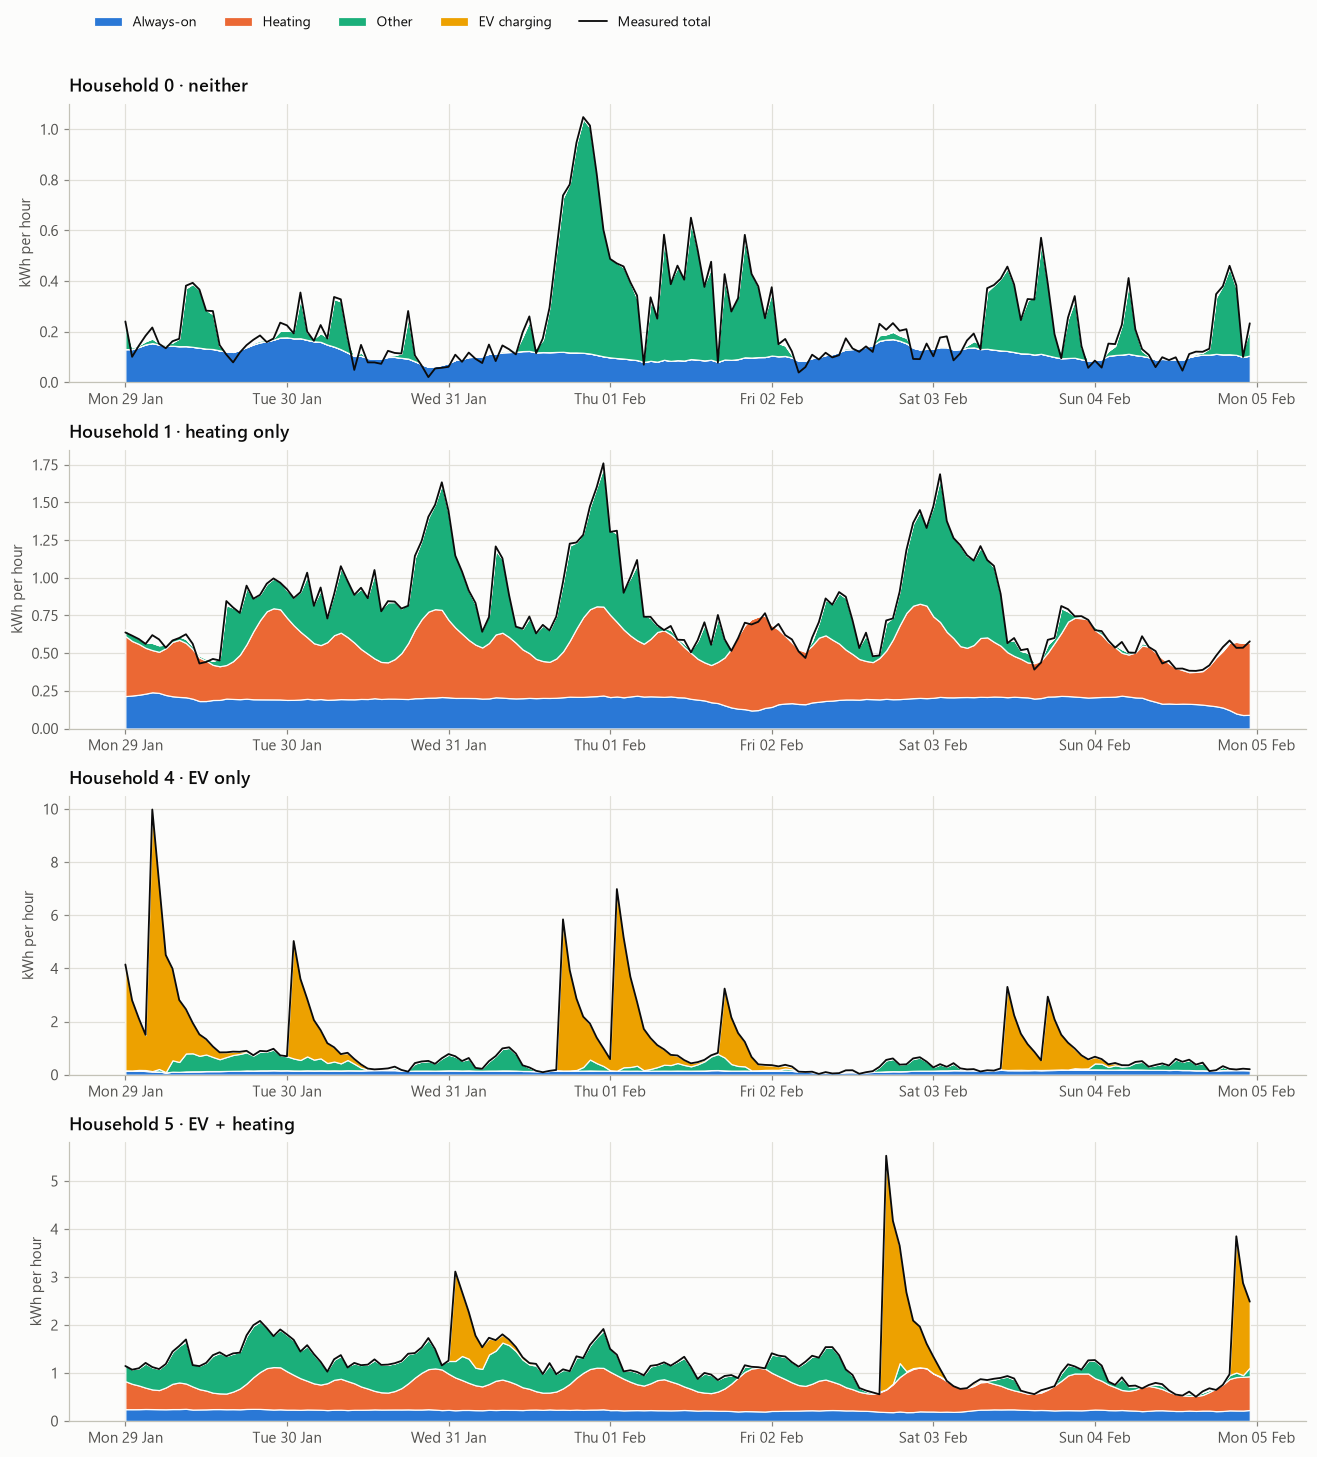

In [25]:
order = ['neither', 'heating only', 'EV only', 'EV + heating']
examples = [(np.where(types == n)[0][0], n) for n in order]
fig, axes = plt.subplots(4, 1, figsize=(12, 13))
s = slice(24 * 28, 24 * 35)
for ax, (i, name) in zip(axes, examples):
    viz.stacked(ax, ts[s], {c: final[c][i, s] for c in viz.STACK}, total=X[i, s], legend=False)
    ax.set_title(f'Household {i} · {name}', pad=8)
    viz.style_dates(ax)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper left', ncol=5, bbox_to_anchor=(0.06, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.98)); fig.savefig(f'{FIG}/gallery.png'); plt.show()

The black line (meter reading) wanders slightly around the top of the stack instead of matching it exactly. That is
intended: the difference is meter noise, which belongs to no component. Always-on (blue) is no longer a flat band.

### Where does the energy go?

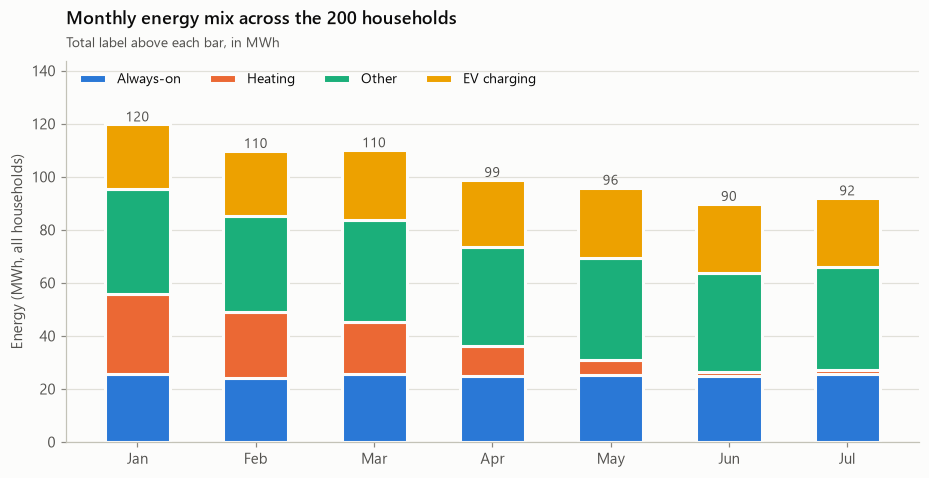

,Always-on %,Heating %,Other %,EV charging %
Jan,21.3,25.3,33.1,20.2
Feb,21.9,22.7,33.0,22.4
Mar,23.4,17.8,35.0,23.8
Apr,25.1,11.7,37.7,25.6
May,26.5,5.9,39.8,27.9
Jun,27.6,1.6,41.9,28.9
Jul,27.8,1.7,42.1,28.4


In [26]:
mix, months = insights.energy_mix(final, ts)
names = pd.to_datetime([f'2024-{m:02d}-01' for m in months]).strftime('%b')
fig, ax = plt.subplots(figsize=(10, 4.5))
bottom = np.zeros(len(months))
for c in viz.STACK:
    ax.bar(names, mix[c], 0.55, bottom=bottom, color=viz.COLORS[c], edgecolor=viz.SURFACE, linewidth=2, label=viz.LABELS[c])
    bottom += mix[c]
for x, b in zip(names, bottom):
    ax.text(x, b, f'{b:.0f}', ha='center', va='bottom', color=viz.INK_2, fontsize=9)
ax.set_ylabel('Energy (MWh, all households)'); ax.grid(axis='x', visible=False)
viz.title(ax, 'Monthly energy mix across the 200 households', 'Total label above each bar, in MWh')
ax.legend(loc='upper left', bbox_to_anchor=(0, 1.0), ncol=4); ax.set_ylim(0, bottom.max() * 1.2)
fig.savefig(f'{FIG}/energy_mix.png'); plt.show()
share = pd.DataFrame({viz.LABELS[c]: mix[c] for c in viz.STACK}, index=names)
(share.div(share.sum(axis=1), axis=0) * 100).round(1).add_suffix(' %')

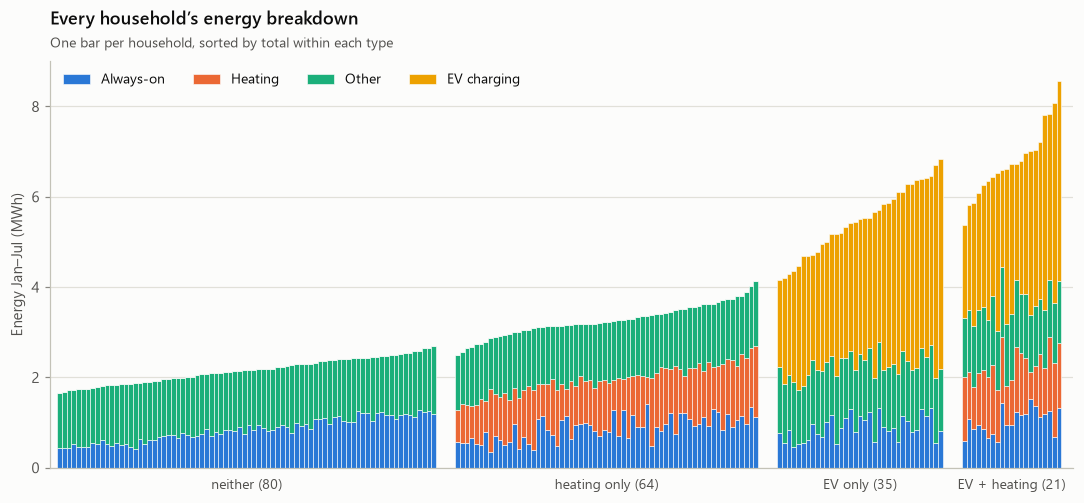

In [27]:
tot = {c: final[c].sum(1) for c in viz.STACK}
grand = sum(tot.values())
fig, ax = plt.subplots(figsize=(12, 4.8))
pos, x0 = [], 0
for name in order:
    rows = np.where(types == name)[0]; rows = rows[np.argsort(grand[rows])]
    xs = x0 + np.arange(len(rows)); pos.append((rows, xs))
    ax.text(xs.mean(), -0.25, f'{name} ({len(rows)})', ha='center', va='top', color=viz.INK_2, fontsize=9)
    x0 += len(rows) + 4
for j, c in enumerate(viz.STACK):
    for g, (rows, xs) in enumerate(pos):
        b = sum(tot[cc][rows] for cc in viz.STACK[:j]) / 1000
        ax.bar(xs, tot[c][rows] / 1000, 1.0, bottom=b, color=viz.COLORS[c], edgecolor=viz.SURFACE, linewidth=0.4,
               label=viz.LABELS[c] if g == 0 else None)
ax.set_xlim(-2, x0 - 2); ax.set_xticks([]); ax.grid(axis='x', visible=False); ax.set_ylim(0, None)
ax.set_ylabel('Energy Jan–Jul (MWh)')
viz.title(ax, 'Every household’s energy breakdown', 'One bar per household, sorted by total within each type')
ax.legend(loc='upper left', ncol=4); fig.savefig(f'{FIG}/households.png'); plt.show()

### What changed from the first model to the final one

In [28]:
pd.DataFrame({
    'v1 (MWh)': {viz.LABELS[c]: res_v1.pred[c].sum() / 1000 for c in viz.STACK},
    'final (MWh)': {viz.LABELS[c]: final[c].sum() / 1000 for c in viz.STACK},
}).assign(**{'change %': lambda d: (d['final (MWh)'] / d['v1 (MWh)'] - 1) * 100}).round(1)

,v1 (MWh),final (MWh),change %
Always-on,199.5,175.8,-11.9
Heating,93.8,95.0,1.2
Other,261.2,266.2,1.9
EV charging,173.2,179.0,3.4


### Where the remaining error is

On the simulator, the HMM model scores **0.00135**, close to the best achievable under its own assumptions (0.00147
vs 0.00153 with true vs estimated parameters in an earlier test). On the real data it reached **0.00213**, and
everything after that (the common heating factor, the megastack, the last calibrations) brought it to **0.00194**.

The rest of the gap is not a bias that any probe could find: section 11 shows the model calibrated in every
direction the leaderboard can measure. It is noise-like error in how always-on and other are split hour by hour,
where the real generator still behaves a little differently from the HMM. The winner's 0.00189 suggests that a
better model of that split was worth another ~3 %.

## 13 · Lessons learned

1. **Look before you clean.** The "outliers" were EV sessions and the "noise" carried structure.
2. **Classification is the easy half.** Owners were identified in a day; magnitudes decided the score.
3. **Pin the generator's rules exactly.** A decay ratio, a threshold, an AR coefficient: each one removes a class
   of errors at once.
4. **Query the metric you cannot compute.** With MSE, a submission is a linear measurement of the hidden truth; compute
   the null score first so the result means something.
5. **Read the residuals.** *Where* the error sits (which hour, which size) names its cause; validate on data the fix
   did not use.
6. **Simulate to find what you are missing.** Score your model on a simulator of everything you believe; the
   real-vs-simulated statistic that disagrees is the missing rule (here: the always-on drift).
7. **Use the likelihood of the observed data** to choose model settings, before spending submissions.
8. **Combine measurements analytically.** Quadratic metric → scored submissions can be stacked with exact weights.
9. **Average across units to find what is shared.** The daily heating factor was invisible in any one household and
   obvious across 85; two disjoint halves separate a shared signal from noise.
10. **Every scored file is a measurement, including the "failed" ones.** Blend them all, but treat the 5-decimal
    rounding as measurement noise and keep only the directions measured well above it.
11. **Probes first, blend last.** A probe only helps a blend submitted *after* it, so each day's probes went first and
    the day ended with the blend that used them.
12. **Calibrated is not the same as precise.** When every measurable direction says "right", the remaining error is
    noise-like, and only a better model can reduce it.
13. **A better likelihood is not a better prediction until the posterior moves.** Measure how much the predictions
    change before spending a submission on a new model.
14. **Engineering matters.** The HMM first ran for 1.5 h because two processes thrashed memory. Measuring each stage,
    logging progress and parallelising across households brought it to ~10 minutes, and a per-household version to
    seconds, which made the last day's likelihood tests possible.

## 14 · Submission, validation and how to reproduce

Kaggle expects `kaggle_id,heating_kWh,ev_kWh,always_on_kWh,other_kWh`, one row per household-hour, **in the same order
as the data file**. `submission.save` numbers each file in upload order and refuses to write it unless every check
passes.

In [29]:
sub = pd.read_csv('../submissions/31_final_megastack_30_files_evhours.csv')
pd.Series(submission.validate(sub, total=X), name='check (submission 31, final)').to_frame()

,"check (submission 31, final)"
header matches,True
row count,"1,022,400 (expected 1,022,400)"
ids identical and in order,True
no NaN / inf,True
no negative values,True
max |sum of parts - total| (kWh),0.3147
READY TO SUBMIT,True


The sum of the four parts differs from the reading by the estimated meter noise, which belongs to no component
(probe 03), so that last check is a size, not a pass/fail.

**Reproduce the final submission** (from `src/`, with the data file in `data/`):

| Step | Command | Time |
|---|---|---|
| v2a, v2b, v2c (fits, EV kernel, calibrations) | `python run_v3.py v2a` (same for `v2b`, `v2c`) | ~1 min each |
| v3, v4 (HMM, 4 processes) | `python run_v3.py v3` · `python run_v3.py v4` | ~10–15 min each |
| v5, v6 (+ common daily heating factor) | `python run_v3.py v5` · `python run_v3.py v6` | ~15 min each |
| HMM settings by likelihood | `python tune_hmm.py 1` … `4` | ~2–5 min per stage |
| Simulator and its scores | `simulate.py` (see section 6) | ~5 min |
| Stack of models (14) | `python make_stack.py v2c v3 v4 v2b v2a` | ~1 min |
| Factor on a cached model (18; 16 used a plain 24 h filter) | `python make_common_heating.py stack14 stack14_heatfactor_v2` | ~1 min |
| Stack of the 9 models (20) | `python make_stack.py v2a v2b v2c v3 v4 stack14_cf v5 stack14_heatfactor_v2 v6 --ridge=1e-5` | ~1 min |
| Calibration probes (21–24, 28, 29) | e.g. `python make_probe.py 20 ao_evhh 0.03` | seconds |
| Megastack (25) | `python megastack.py --base=20 --save` (with files 01–24 scored) | ~2 min |
| **Final (31)** | **`python make_final.py`** (with files 01–30 scored) | ~3 min |

The megastack and the final step read the scored submission files and `results/leaderboard.csv`, which logs every
submission with the question it answered.